In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing, model_selection, metrics

# Carga de Dataframes modificados

In [2]:
df_labeled_all = pd.read_parquet('../Data_parcial2_mineria/df_labeled_all.parquet')
df_labeled = pd.read_parquet('../Data_parcial2_mineria/df_labeled.parquet')

df_unlabeled_all = pd.read_parquet('../Data_parcial2_mineria/df_unlabeled_all.parquet')
df_unlabeled = pd.read_parquet('../Data_parcial2_mineria/df_unlabeled.parquet')

In [3]:
df_unlabeled = df_unlabeled.rename(columns = {"Period_fit": "PPE"})
labels_classALeRCE = ['SNIa', 'SNIbc', 'SNII', 'SLSN','QSO','AGN', 'Blazar', 'YSO','CV/Nova',
                       'LPV', 'E', 'DSCT', 'RRL', 'CEP','Periodic-Other']

## Definir función para mostrar importancias

In [4]:
def plot_feature_importances(model, feature_names, title):
    I = np.argsort(model.feature_importances_)[::-1]
    I = I[0:60]
    for i in I[0:30]:
        print(feature_names[i], "& %.3f" % (model.feature_importances_[i]))
    fig, ax = plt.subplots(figsize=(16, 5), tight_layout=True)
    x_plot = np.arange(len(I))
    plt.xticks(x_plot, [feature_names[i] for i in I], rotation='vertical')
    ax.bar(x_plot, height=model.feature_importances_[I]);
    plt.title(title)
    plt.show()

# BRF Implementado

El algoritmo que finalmente es implementado para LSST es entrenado con todos los datos etiquetados y fue testeado con los datos sin etiquetar

In [5]:
X_tr = df_labeled.iloc[:, 1:153]
y_tr1, y_tr2 = df_labeled['classTop'], df_labeled['classALeRCE']

X_ts = df_unlabeled.iloc[:, 1:]

In [6]:
X_tr_Stochastic = X_tr.loc[y_tr1 == 'Stochastic', :]
y_tr_Stochastic = y_tr2.loc[y_tr1 == 'Stochastic']

X_tr_Periodic = X_tr.loc[y_tr1 == 'Periodic', :]
y_tr_Periodic = y_tr2.loc[y_tr1 == 'Periodic']

X_tr_Transient = X_tr.loc[y_tr1 == 'Transient', :]
y_tr_Transient = y_tr2.loc[y_tr1 == 'Transient']

X_ts_Stochastic = X_ts
X_ts_Periodic = X_ts
X_ts_Transient = X_ts

print(f'Stochastic sub-classes: {y_tr_Stochastic.unique()} \n')
print(f'Periodic sub-classes: {y_tr_Periodic.unique()} \n')
print(f'Transient sub-classes: {y_tr_Transient.unique()} \n')

Stochastic sub-classes: <ArrowStringArray>
['AGN', 'Blazar', 'CV/Nova', 'QSO', 'YSO']
Length: 5, dtype: str 

Periodic sub-classes: <ArrowStringArray>
['CEP', 'DSCT', 'E', 'LPV', 'Periodic-Other', 'RRL']
Length: 6, dtype: str 

Transient sub-classes: <ArrowStringArray>
['SLSN', 'SNII', 'SNIa', 'SNIbc']
Length: 4, dtype: str 



# Primer Nivel

In [7]:
from imblearn.ensemble import BalancedRandomForestClassifier as RandomForestClassifier

# Estos hiperparámetros son extraidos directamente del código publicado en el artículo
BRF1 = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',   #en el artículo se coloca 'auto', pero son lo mismo segun la documentación de imblearn
            max_depth=None,
            n_jobs=-1,
            bootstrap=True,
            class_weight='balanced_subsample',
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1
    )

BRF1.fit(X_tr, y_tr1)

y_pred = BRF1.predict(X_ts)
y_pred_proba_BRF1 = BRF1.predict_proba(X_ts)

#organizar por probabilidad
classes_order_proba_BRF1 = BRF1.classes_
print(classes_order_proba_BRF1)

features = list(X_tr)

['Periodic' 'Stochastic' 'Transient']


W1-W2 & 0.093
positive_fraction_2 & 0.054
positive_fraction_1 & 0.049
sgscore1 & 0.043
LinearTrend_2 & 0.036
SPM_chi_1 & 0.035
SPM_tau_rise_1 & 0.033
g-W3 & 0.030
g-W2 & 0.029
SPM_beta_1 & 0.029
W2-W3 & 0.027
SPM_A_2 & 0.026
n_non_det_after_fid_2 & 0.025
SPM_chi_2 & 0.025
SPM_A_1 & 0.019
ExcessVar_2 & 0.018
SPM_tau_rise_2 & 0.017
ExcessVar_1 & 0.016
r-W3 & 0.015
r-W2 & 0.015
LinearTrend_1 & 0.012
SPM_tau_fall_1 & 0.012
SPM_beta_2 & 0.012
Rcs_2 & 0.011
GP_DRW_sigma_2 & 0.011
SPM_t0_1 & 0.010
Meanvariance_1 & 0.009
Meanvariance_2 & 0.009
Pvar_1 & 0.009
MHPS_low_2 & 0.008


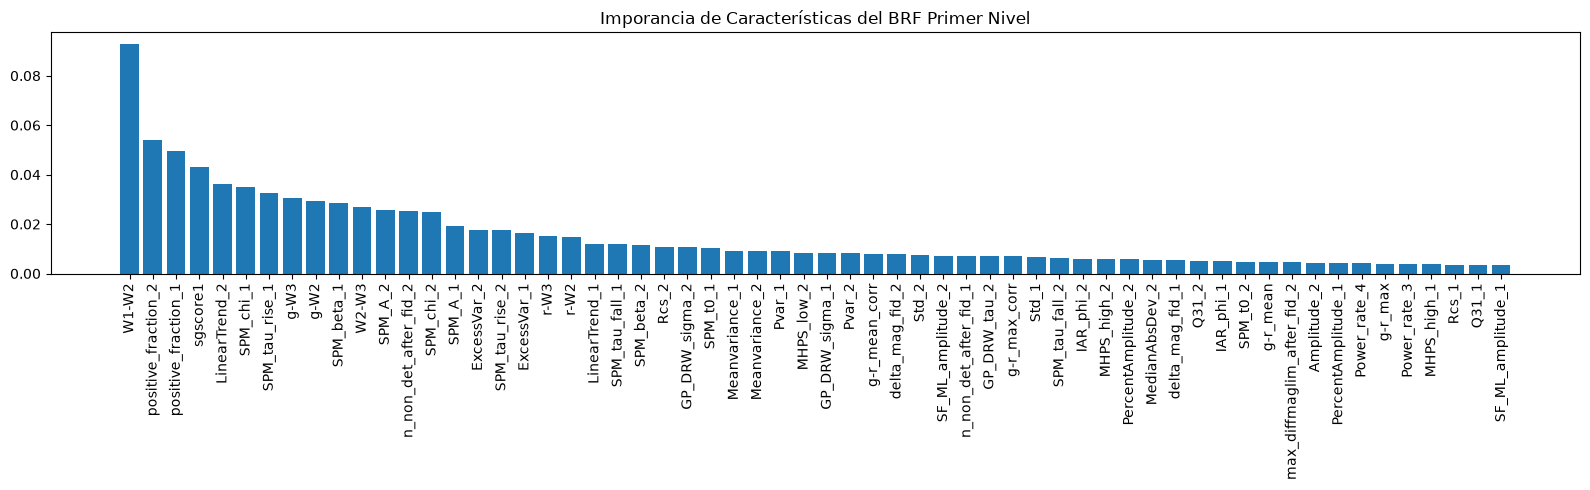

In [8]:
plot_feature_importances(BRF1, features, "Imporancia de Características del BRF Primer Nivel")

## BRF Segundo Nivel

### BRF Periodic

In [9]:
BRF2_periodic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_periodic.fit(X_tr_Periodic, y_tr_Periodic)

y_pred_periodic = BRF2_periodic.predict(X_ts_Periodic)
y_pred_proba_periodic = BRF2_periodic.predict_proba(X_ts_Periodic)

#organizar por probabilidad
classes_order_proba_periodic = BRF2_periodic.classes_
print(classes_order_proba_periodic)

features_periodic = list(X_tr_Periodic)

['CEP' 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


Multiband_period & 0.093
g-W2 & 0.061
g-r_max_corr & 0.030
r-W2 & 0.030
g-r_mean & 0.029
g-W3 & 0.027
g-r_max & 0.024
g-r_mean_corr & 0.024
IAR_phi_1 & 0.022
GP_DRW_tau_1 & 0.021
r-W3 & 0.019
Meanvariance_1 & 0.019
delta_mag_fid_1 & 0.018
Amplitude_1 & 0.015
Std_1 & 0.015
ExcessVar_1 & 0.015
GP_DRW_sigma_1 & 0.014
PercentAmplitude_1 & 0.012
GP_DRW_tau_2 & 0.011
W1-W2 & 0.010
Autocor_length_1 & 0.009
W2-W3 & 0.009
SF_ML_amplitude_1 & 0.009
SF_ML_gamma_1 & 0.008
IAR_phi_2 & 0.008
Gskew_1 & 0.008
SPM_A_1 & 0.008
Amplitude_2 & 0.008
Q31_1 & 0.008
delta_mag_fid_2 & 0.007


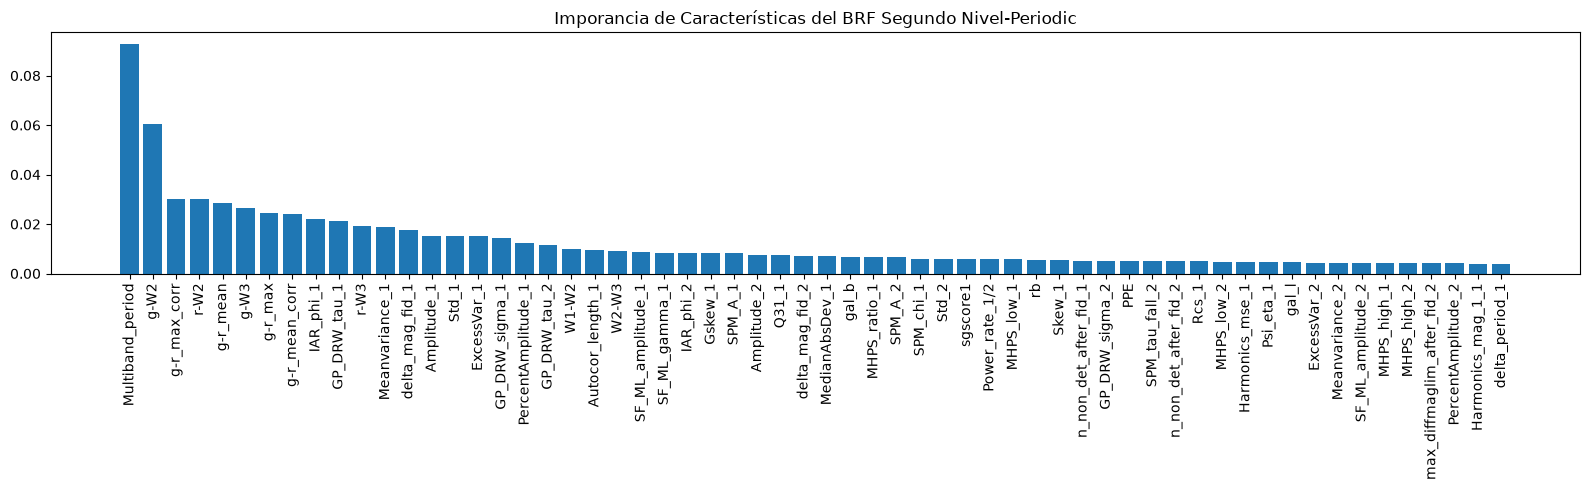

In [10]:
plot_feature_importances(BRF2_periodic, features_periodic, "Imporancia de Características del BRF Segundo Nivel-Periodic")

### BRF Stochastic

In [11]:
BRF2_stochastic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_stochastic.fit(X_tr_Stochastic, y_tr_Stochastic)

y_pred_stochastic = BRF2_stochastic.predict(X_ts_Stochastic)
y_pred_proba_stochastic = BRF2_stochastic.predict_proba(X_ts_Stochastic)

#organizar por probabilidad
classes_order_proba_stochastic = BRF2_stochastic.classes_
print(classes_order_proba_stochastic)

features_stochastic = list(X_tr_Stochastic)

['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO']


W1-W2 & 0.066
g-r_mean_corr & 0.041
g-W2 & 0.040
sgscore1 & 0.040
g-W3 & 0.038
r-W2 & 0.037
gal_b & 0.034
g-r_max_corr & 0.033
W2-W3 & 0.026
g-r_mean & 0.024
r-W3 & 0.023
ExcessVar_2 & 0.021
delta_mag_fid_2 & 0.020
Meanvariance_2 & 0.020
SPM_A_2 & 0.019
Amplitude_2 & 0.018
g-r_max & 0.017
Std_2 & 0.016
PercentAmplitude_2 & 0.016
IAR_phi_1 & 0.014
ExcessVar_1 & 0.013
GP_DRW_sigma_2 & 0.013
SPM_A_1 & 0.012
delta_mag_fid_1 & 0.012
Pvar_2 & 0.011
PercentAmplitude_1 & 0.010
Meanvariance_1 & 0.009
GP_DRW_tau_1 & 0.009
IAR_phi_2 & 0.009
MedianAbsDev_2 & 0.009


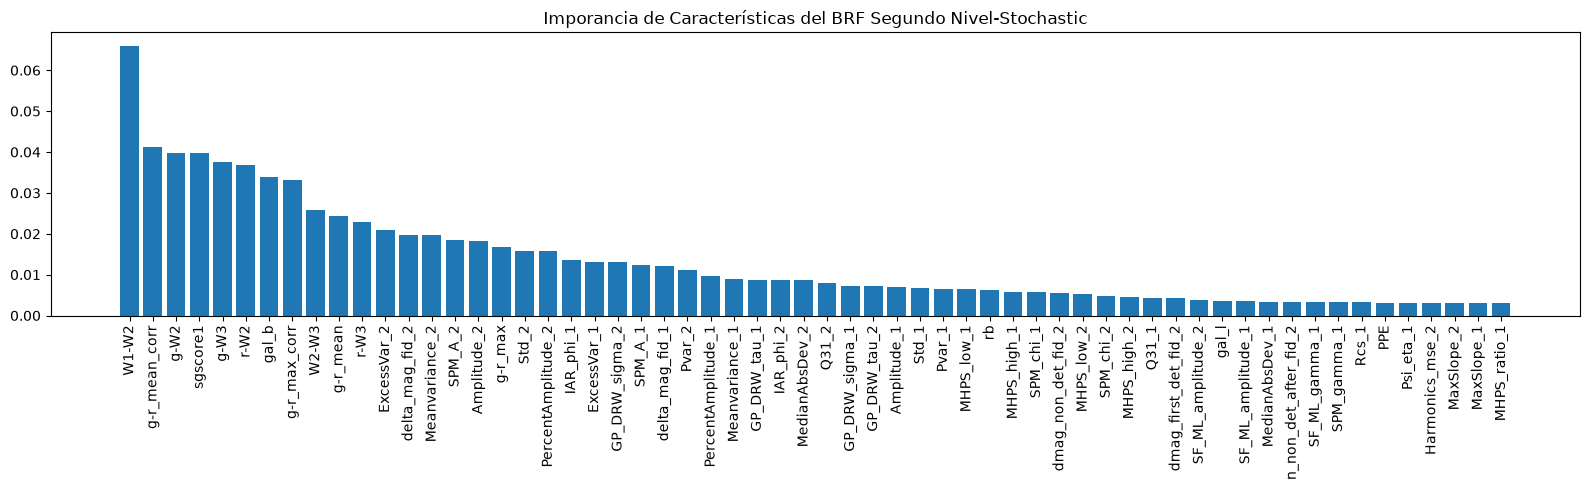

In [12]:
plot_feature_importances(BRF2_stochastic, features_stochastic, "Imporancia de Características del BRF Segundo Nivel-Stochastic")

### BRF Transient

In [13]:
BRF2_transient = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_transient.fit(X_tr_Transient, y_tr_Transient)

y_pred_transient = BRF2_transient.predict(X_ts_Transient)
y_pred_proba_transient = BRF2_transient.predict_proba(X_ts_Transient)

#organizar por probabilidad
classes_order_proba_transient = BRF2_transient.classes_
print(classes_order_proba_transient)

features_transient = list(X_tr_Transient)

['SLSN' 'SNII' 'SNIa' 'SNIbc']


SPM_beta_2 & 0.035
SPM_t0_1 & 0.029
SPM_t0_2 & 0.025
g-r_max & 0.024
LinearTrend_2 & 0.022
SPM_tau_rise_2 & 0.022
SPM_beta_1 & 0.017
MHPS_ratio_1 & 0.016
SPM_tau_fall_2 & 0.016
SPM_tau_rise_1 & 0.016
MHPS_low_1 & 0.015
SPM_tau_fall_1 & 0.014
g-r_mean & 0.014
LinearTrend_1 & 0.013
AndersonDarling_2 & 0.013
dmag_first_det_fid_1 & 0.012
dmag_first_det_fid_2 & 0.011
SPM_gamma_2 & 0.010
IAR_phi_1 & 0.010
IAR_phi_2 & 0.010
sgscore1 & 0.010
MHPS_ratio_2 & 0.010
SPM_A_2 & 0.009
MHPS_low_2 & 0.008
Skew_2 & 0.008
GP_DRW_tau_1 & 0.008
Psi_CS_1 & 0.008
Power_rate_2 & 0.008
Gskew_1 & 0.008
Power_rate_4 & 0.008


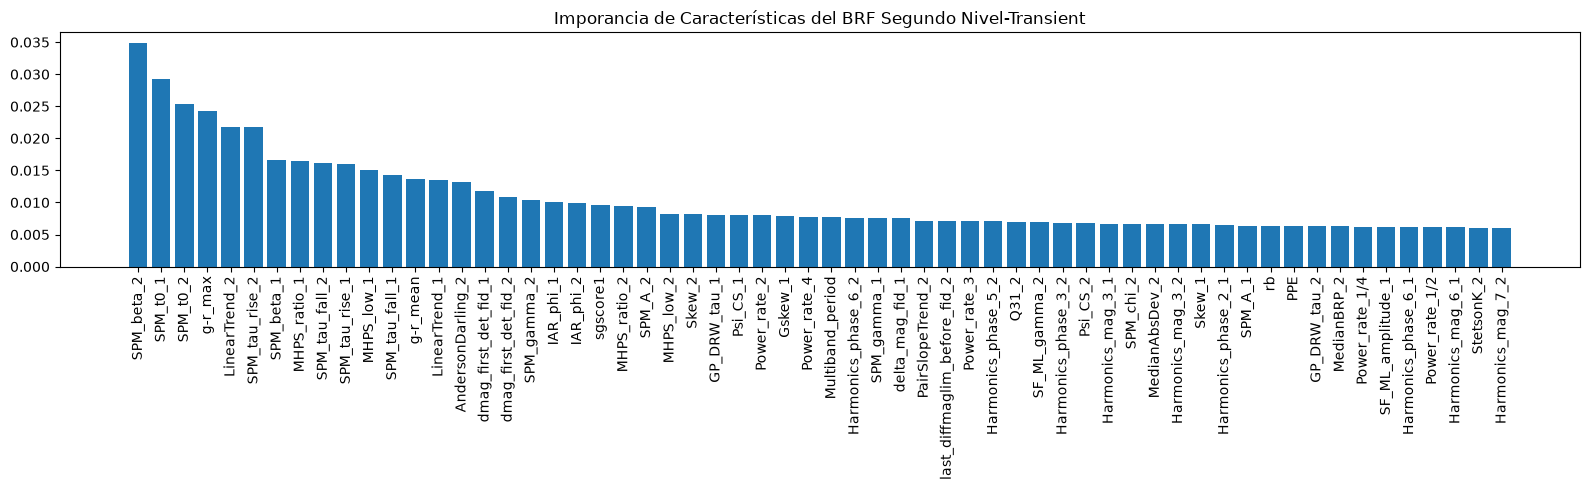

In [14]:
plot_feature_importances(BRF2_transient, features_transient, "Imporancia de Características del BRF Segundo Nivel-Transient")

### Determinar la Clase a Partir de Probabilidades

In [15]:
# generar probabilidades finales

#multiplicar la probabilidad del primer nivel por la del segundo
prob_periodic = y_pred_proba_periodic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Periodic')[0][0]].T[:, np.newaxis]
prob_stochastic = y_pred_proba_stochastic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Stochastic')[0][0]].T[:, np.newaxis]
prob_trainsient = y_pred_proba_transient*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Transient')[0][0]].T[:, np.newaxis]

#matriz final de probabilidades
#una columna para cada subclase, una fila para cada instancia
prob_final = np.concatenate((prob_stochastic,prob_trainsient,prob_periodic),axis=1)
print(f"Tamaño de Matriz de probabilidades: ", prob_final.shape)

#veificar funcionamiento adecuado. Suma las filas, la suma debe ser 1
print(f"Suma de columnas: {np.sum(prob_final,axis=1)}", f"Promedio: {np.mean(np.sum(prob_final,axis=1))}", f"Desviación Estándar: {np.std(np.sum(prob_final,axis=1))}")

#organizar los nombres de las clases igual que en prob_final
prob_final_class_names = np.concatenate((classes_order_proba_stochastic,classes_order_proba_transient,classes_order_proba_periodic))
print(prob_final_class_names)

#extrae la probabilidad mayor en cada fila y el nombre de la lase a la que corresponde
class_final_proba = np.amax(prob_final,axis=1)
class_final_index = np.argmax(prob_final,axis=1)
class_final_name = [prob_final_class_names[x] for x in class_final_index]

Tamaño de Matriz de probabilidades:  (744875, 15)
Suma de columnas: [1. 1. 1. ... 1. 1. 1.] Promedio: 1.0 Desviación Estándar: 8.68356456738041e-17
['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO' 'SLSN' 'SNII' 'SNIa' 'SNIbc' 'CEP'
 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


# Verificación

Debido a que no se cuenta con etiquetas para el conjunto de testeo es necesario recurrir a otros métodos para verificar la efectividad del clasificador

## Distribución de probabilidades para cada clase

In [16]:
df_p = pd.DataFrame({'clase': class_final_name, 'prob': class_final_proba})

In [17]:
df_p

,clase,prob
0,Periodic-Other,0.368220
1,E,0.637440
2,Periodic-Other,0.439296
3,LPV,0.986040
4,E,0.481176
...,...,...
744870,SNIa,0.311808
744871,AGN,0.636696
744872,QSO,0.801312
744873,SNIa,0.251600


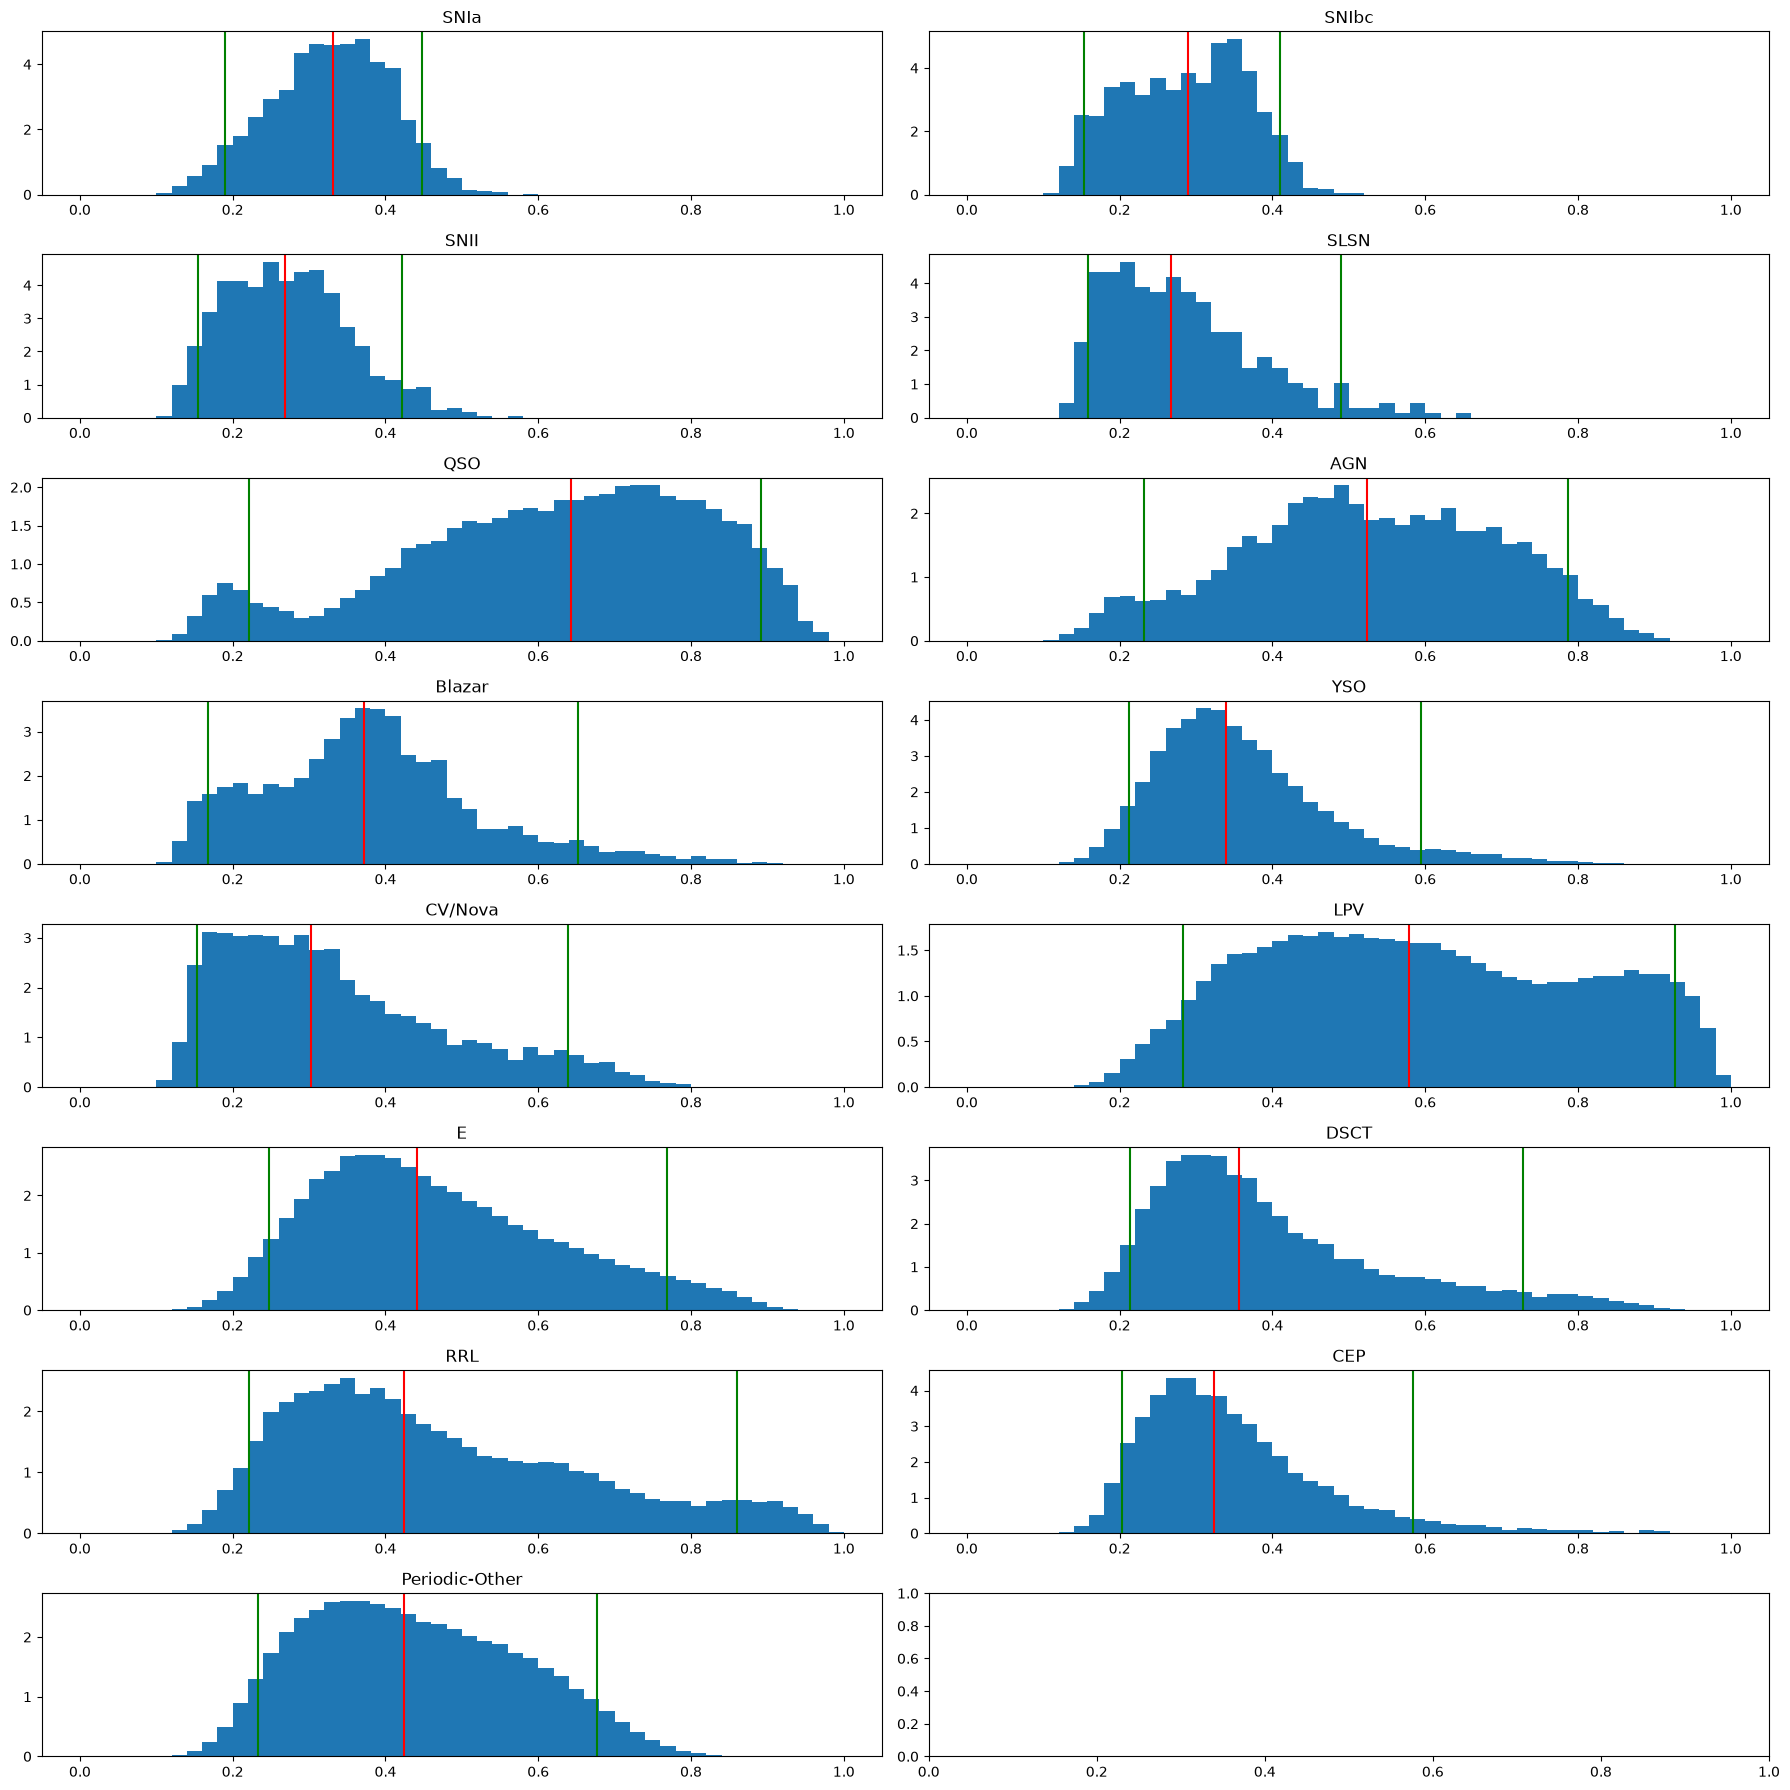

In [18]:
clases = labels_classALeRCE
fig, axes = plt.subplots(8, 2, figsize=(18, 18), sharey=False)
for ax, c in zip(axes.ravel(), clases):
    p = df_p.loc[df_p.clase == c, 'prob']
    ax.hist(p, bins=50, range=(0, 1), density=True)
    ax.axvline(p.median(), color='r')
    ax.axvline(p.quantile(0.05), color='g')
    ax.axvline(p.quantile(0.95), color='g')
    ax.set_title(f'{c}')
plt.tight_layout(); plt.show()

## Comportamiento esperado de objetos Galácticos y Extragalácticos

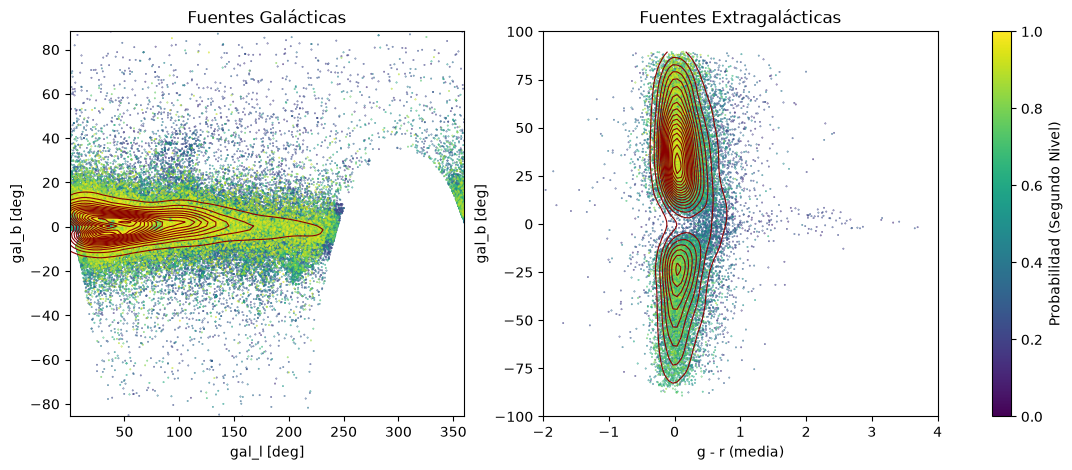

In [19]:
from scipy.stats import gaussian_kde

classes = np.array(class_final_name)
prob = np.asarray(class_final_proba)

galact = ['LPV', 'CEP', 'YSO']
extragal = ['QSO', 'AGN', 'Blazar', 'SNIa', 'SNIbc', 'SNII', 'SLSN']

# gal_b vs gal_l (fuentes galácticas)
m = np.isin(classes, galact)
l = df_unlabeled['gal_l'].values[m]
b = df_unlabeled['gal_b'].values[m]
p = prob[m]

# gal_b vs g-r (fuentes extragalácticas)
m2 = np.isin(classes, extragal)
gr = df_unlabeled['g-r_mean'].values[m2]
b2 = df_unlabeled['gal_b'].values[m2]
p2 = prob[m2]
valid = gr > -900          # descarta las bandas faltantes
gr, b2, p2 = gr[valid], b2[valid], p2[valid]

def panel(ax, x, y, p, xlabel):
    orden = np.argsort(p)   # los de mayor prob. quedan encima
    sc = ax.scatter(x[orden], y[orden], c=p[orden], s=0.1, cmap='viridis',
                    vmin=0, vmax=1, rasterized=True)
    # contornos de densidad
    sub = np.random.choice(len(x), min(len(x), 20000), replace=False)
    kde = gaussian_kde(np.vstack([x[sub], y[sub]]))
    gx = np.linspace(x.min(), x.max(), 100)
    gy = np.linspace(y.min(), y.max(), 100)
    X, Y = np.meshgrid(gx, gy)
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    ax.contour(X, Y, Z, levels=20, colors='darkred', linewidths=0.8)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('gal_b [deg]')
    return sc

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
panel(axes[0], l, b, p, 'gal_l [deg]')
sc = panel(axes[1], gr, b2, p2, 'g - r (media)')
axes[0].set_title('Fuentes Galácticas')
axes[1].set_title('Fuentes Extragalácticas')
axes[1].set_xlim(-2, 4)
axes[1].set_ylim(-100, 100)
fig.colorbar(sc, ax=axes, label='Probabilidad (Segundo Nivel)')
plt.show()

## Distribución de Magnitudes en r

Otra forma de verificar el funcionamiento del modelo es comparando las distribuciones de magnitudes en los datos etiquetados y en las predicciones. La similitud entre las distribuciones de cada clase significaría un funcionamiento adecuado.

Esta comparación funcionaría para cualquiera de las magnitudes pero aqui se muestra solo para la banda r

In [20]:
labeled_mag = df_labeled_all[['classALeRCE', 'Mean_2']]
labeled_mag.fillna(-999)

,classALeRCE,Mean_2
0,AGN,18.299832
1,AGN,-999.000000
2,AGN,-999.000000
3,AGN,18.243364
4,AGN,17.524334
...,...,...
123491,YSO,14.278745
123492,YSO,-999.000000
123493,YSO,13.471936
123494,YSO,-999.000000


In [21]:
unlabeled_mag = pd.DataFrame({'classALeRCE': class_final_name, 'Mean_2': df_unlabeled_all['Mean_2']})
unlabeled_mag.fillna(-999)

,classALeRCE,Mean_2
0,Periodic-Other,17.118709
1,E,17.096904
2,Periodic-Other,16.744352
3,LPV,14.677696
4,E,15.482238
...,...,...
868365,SNIa,19.274447
868366,AGN,-999.000000
868367,QSO,-999.000000
868368,SNIa,18.600268


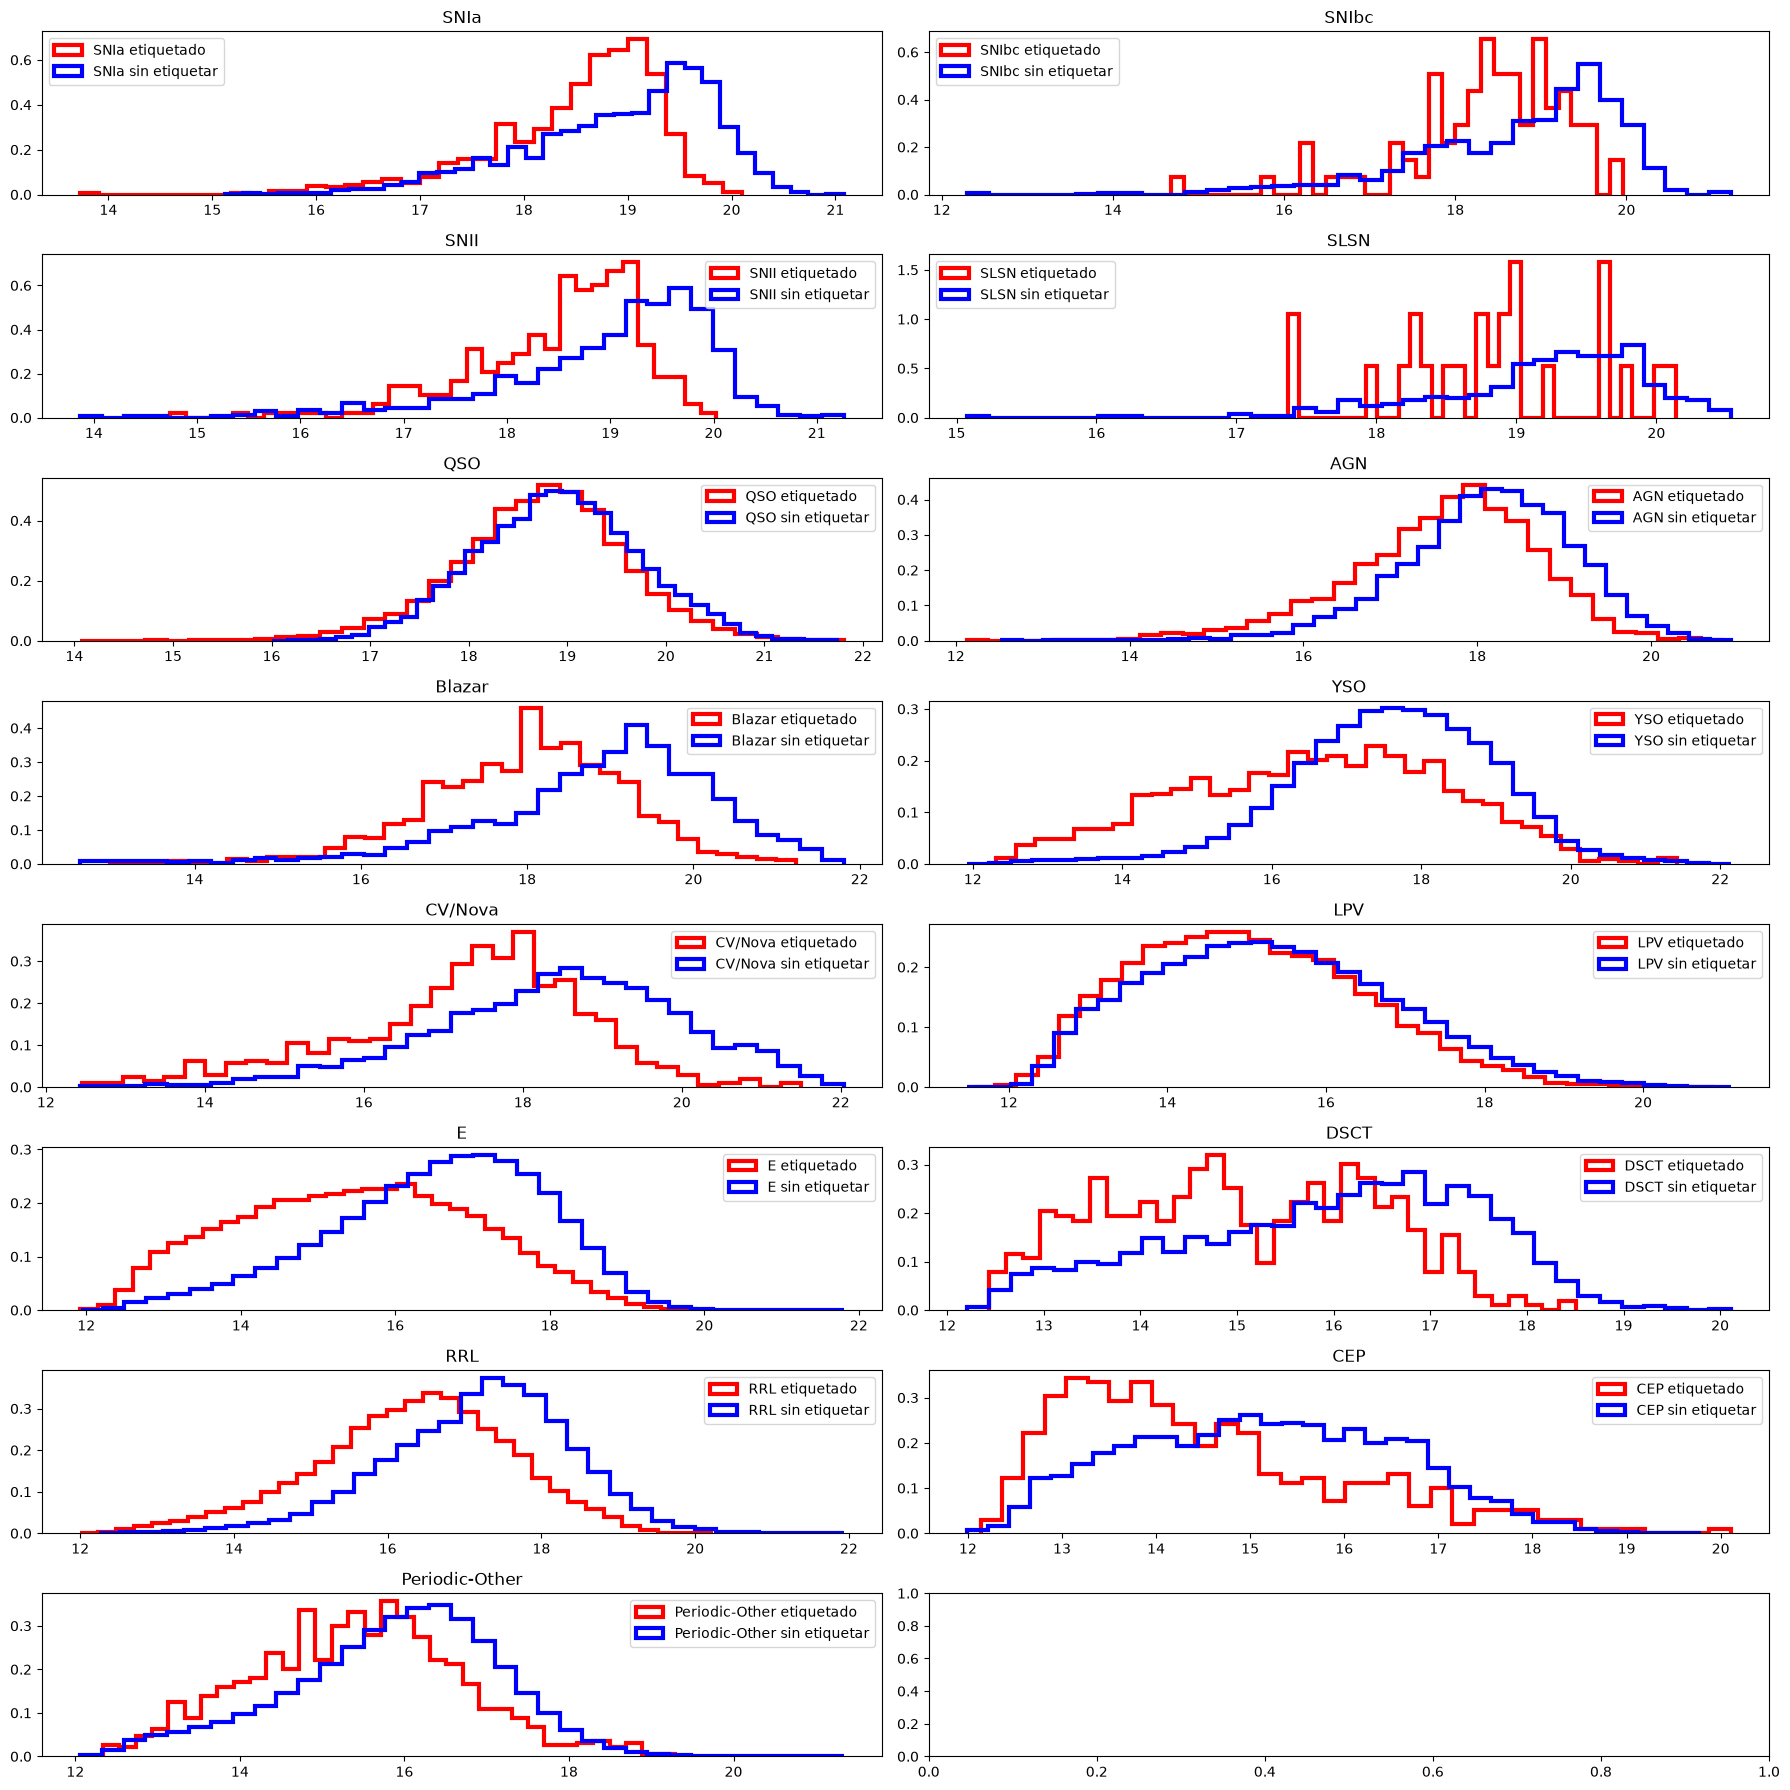

In [22]:
fig, axes = fig, axes = plt.subplots(8, 2, figsize=(18, 18), sharey=False)
for ax, c, in zip(axes.ravel(), clases):
    mag_lab = labeled_mag.loc[labeled_mag.classALeRCE == c, 'Mean_2']
    mag_unlab = unlabeled_mag.loc[unlabeled_mag.classALeRCE == c, 'Mean_2']

    ax.hist(mag_lab, bins=35, density=True, histtype="step", color='red', label= f'{c} etiquetado', linewidth=3)
    ax.hist(mag_unlab, bins=35, density=True, histtype="step", color='blue', label= f'{c} sin etiquetar', linewidth=3)

    ax.legend()
    ax.set_title(f'{c}')
plt.tight_layout(); plt.show()